# 03 — Does radiation change the tumour cell itself?

`01`/`02`/`02b` asked what the tumour is *made of*. This notebook asks what the tumour cell
*is doing* — the four programs through which radiation is supposed to help a CAR-T:

| program family | the RT-helps-CAR-T argument | genes / sets |
|---|---|---|
| **antigen presentation** | RT raises MHC-I, so tumour cells are easier to see | curated MHC-I machinery, Reactome class-I / class-II |
| **interferon** | RT -> cytosolic DNA -> cGAS-STING -> type-I IFN | curated ISG core, Hallmark IFN-alpha / IFN-gamma, Reactome STING |
| **death-receptor sensitivity** | RT raises Fas / DR5, sensitising to CAR-T killing | curated Fas/DR5/caspase-8 axis, anti-apoptotic axis, Reactome TRAIL / death receptor |
| **senescence / SASP** | RT-induced senescence secretes chemokines that recruit T cells | curated p21/p16 + SASP core, Reactome senescence / SASP |

plus a **p53 / DNA-damage** family (the most direct trace the beam could leave in a tumour cell)
and a **control tier** (proliferation, OXPHOS, MYC, EMT, hypoxia).

### What `09` already says, and why this is not a re-run of it
`09 §E` ran a whole-transcriptome reproducibility test in `Cancer_cell` and found RT at chance
(cross-background logFC r inside its permutation null). That test asks *"does the whole
transcriptome move the same way in both backgrounds?"*. It can miss a focused shift in a
15-gene program buried in 8,000 genes, and it was not site-resolved. This notebook asks the
narrower, a-priori question — **these programs, at each site, and within mouse** — and scores
each against a null built from random programs of the same size and expression level.

### Rules carried in from `01`/`02b`
* Every contrast is *"adding RT on top of Cy + CAR-T"*, site-matched, once per CAR background.
* `02b` found the `CAR x RT` interaction larger than the RT main effect, so **each background is
  read on its own**, and the interaction is printed beside the main effect. Sign agreement is
  still what earns a main-effect claim.
* The `Tu1`/`Tu2` site difference exists without RT, so within-mouse contrasts are run as a
  **difference-in-differences**.
* `NoTx` is a pipeline check only.

### The trap specific to this notebook — ambient RNA
Tumour cells are 4-6% of a treated sample and macrophages ~50%. Interferon genes in a
`Cancer_cell` pseudobulk can be macrophage RNA. §6 builds a macrophage pseudobulk from the same
samples, flags **myeloid-dominant genes**, and re-scores every program without them.

## 1. Config

In [1]:
import warnings; warnings.filterwarnings("ignore")
import itertools, time
from pathlib import Path
import numpy as np, pandas as pd, h5py, anndata as ad
import scipy.sparse as sp
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy import stats

pd.set_option("display.width", 260); pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 300)

_HPC = Path("/coh_labs/yunroseli/Jona/CAR-T")
_LOC = Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ = _HPC if _HPC.exists() else _LOC
SC_REF = (PROJ/"data/zarr/fullDataset/annotating_references/annotation_v4.h5ad"
          if PROJ is _HPC else PROJ/"data/sc-reference/annotation_v4.h5ad")
GMT_DIR = PROJ/"data/references/pathways"
OUT = PROJ/"results/rt_advantage"; FIG = OUT/"figures"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

# arm naming: single cell spells the non-specific arm CyTAG72, spatial spells it CyT72
SC2ARM = {"NoTx": "NoTx", "CyPSCA": "CyPSCA", "CyTAG72": "CyT72",
          "RTCyPSCA": "RTCyPSCA", "RTCyTAG72": "RTCyT72"}
CART_PAIRS = [("PSCA", "RTCyPSCA", "CyPSCA"), ("TAG72", "RTCyT72", "CyT72")]
CAR_PAIRS  = [("nonRT", "CyPSCA", "CyT72"), ("RT", "RTCyPSCA", "RTCyT72")]   # the CAR axis
SITE = {1: "irradiated", 2: "abscopal"}
ARM_ORDER = ["NoTx", "CyPSCA", "CyT72", "RTCyPSCA", "RTCyT72"]
COL = {"NoTx": "#9e9e9e", "CyPSCA": "#3b6ea5", "CyT72": "#7fa7d1",
       "RTCyPSCA": "#d1495b", "RTCyT72": "#ec9a9a"}

TUMOUR   = ["Cancer_cell"]
MACS     = ["M1_like_Mac", "M2_like_Mac", "Intermediate_Mac"]
MIN_CELLS      = 20      # per-sample floor for a usable pseudobulk
MIN_CPM        = 10      # gene kept if mean CPM >= this in the tumour pseudobulks ...
MIN_DET_FRAC   = 0.5     # ... and counted in >= this fraction of samples
MIN_PROG_GENES = 4       # a program needs this many kept genes to be scored
MYELOID_RATIO  = 4.0     # gene is "myeloid-dominant" if mac CPM / tumour CPM exceeds this
N_RANDOM       = 1000    # random expression-matched programs per real program
SEED = 0
rng = np.random.default_rng(SEED)
print(f"PROJ = {PROJ}\nOUT  = {OUT}")

PROJ = /Users/janzules/Roselab/Spatial/CAR_T
OUT  = /Users/janzules/Roselab/Spatial/CAR_T/results/rt_advantage


## 2. Load, rebuild the design, and read raw counts for tumour cells and macrophages

`.X` is log-normalised in this object and `layers/counts` is raw (checked in `09`). Pseudobulk
is the **sum of raw counts** per sample — one observation per sample, not per cell, and no
per-cell library-complexity term (the artifact that produced `09`'s fake `TNFA_NFKB` signal).

Only the rows needed are read from the 3 GB counts layer, in contiguous runs.

In [2]:
with h5py.File(SC_REF, "r") as f:
    o = ad.io.read_elem(f["obs"])
    var = ad.io.read_elem(f["var"])
genes = pd.Index(var.index.astype(str))
print(f"{len(o):,} cells x {len(genes):,} genes")

o["sample"] = o["file_name"].astype(str)
p = o["sample"].str.extract(r"^(?P<sc>.+)_Tu(?P<site>\d)_(?P<rep>\d+)$")
assert p.notna().all().all(), "file_name did not parse"
o["arm"]   = p["sc"].map(SC2ARM)
o["site"]  = p["site"].astype(int)
o["mouse"] = p["sc"] + "_m" + p["rep"]
o["ct"]    = o["cell_type_lvl2"].astype(str)
assert o["arm"].notna().all(), f"unmapped arms: {set(p.loc[o.arm.isna(), 'sc'])}"

design = (o.groupby("sample", observed=True)
            .agg(arm=("arm", "first"), site=("site", "first"), mouse=("mouse", "first"),
                 n_cells=("arm", "size")))
design["RT"]   = design.arm.str.startswith("RT")
design["cart"] = design.arm.map({"CyPSCA": "PSCA", "RTCyPSCA": "PSCA", "CyT72": "TAG72",
                                 "RTCyT72": "TAG72", "NoTx": "none"})


def read_csr_rows(path, rows, layer="layers/counts"):
    """Rows of an on-disk CSR matrix, read in contiguous runs. Returns CSR in sorted-row order."""
    rows = np.sort(np.asarray(rows))
    with h5py.File(path, "r") as f:
        g = f[layer]
        ncol = int(g.attrs["shape"][1])
        indptr = g["indptr"][:]
        blocks = []
        for run in np.split(rows, np.where(np.diff(rows) != 1)[0] + 1):
            a, b = indptr[run[0]], indptr[run[-1] + 1]
            ptr = indptr[run[0]:run[-1] + 2] - a
            blocks.append(sp.csr_matrix((g["data"][a:b], g["indices"][a:b], ptr),
                                        shape=(len(run), ncol)))
    return sp.vstack(blocks).tocsr(), rows


def pseudobulk(cell_types):
    m = o["ct"].isin(cell_types).values
    t0 = time.time()
    C, rows = read_csr_rows(SC_REF, np.where(m)[0])
    smp = o["sample"].values[rows]
    n = pd.Series(smp).value_counts()
    ok = [s for s in design.index if n.get(s, 0) >= MIN_CELLS]
    M = np.vstack([np.asarray(C[smp == s].sum(0)).ravel() for s in ok])
    assert float(C.data[:1000].max()) == int(C.data[:1000].max()), "counts layer is not integer"
    print(f"  {'+'.join(cell_types)[:40]:<40s} {m.sum():>7,} cells read in {time.time()-t0:.0f}s"
          f" | {len(ok)}/{len(design)} samples >= {MIN_CELLS} cells"
          f" | dropped: {[s for s in design.index if s not in ok]}")
    return pd.DataFrame(M, index=ok, columns=genes), n.reindex(ok)


PB_T, NC_T = pseudobulk(TUMOUR)
PB_M, NC_M = pseudobulk(MACS)
design["n_tumour"] = NC_T.reindex(design.index)
design["n_mac"]    = NC_M.reindex(design.index)
print("\ntumour cells per sample, by arm x site:")
print(design.pivot_table(index="arm", columns="site", values="n_tumour", aggfunc=list)
        .rename(columns=SITE).reindex(ARM_ORDER).to_string())

93,548 cells x 22,949 genes


  Cancer_cell                                6,614 cells read in 3s | 29/29 samples >= 20 cells | dropped: []


  M1_like_Mac+M2_like_Mac+Intermediate_Mac  48,475 cells read in 9s | 29/29 samples >= 20 cells | dropped: []

tumour cells per sample, by arm x site:
site           irradiated         abscopal
arm                                       
NoTx      [175, 448, 437]  [229, 745, 598]
CyPSCA     [164, 96, 189]    [93, 127, 36]
CyT72          [291, 228]  [117, 144, 415]
RTCyPSCA  [174, 141, 246]   [70, 203, 264]
RTCyT72   [297, 139, 163]   [119, 45, 221]


## 3. Normalise, and the program panel

`log2(CPM + 1)` on the summed counts, genes filtered on the tumour pseudobulks, then each gene
z-scored **across the treated samples** (so `NoTx`, a different tissue state, does not set the
scale). A program's score is the mean z of its kept genes — in units of "between-sample SDs of
an average member gene", which makes programs comparable to each other.

In [3]:
def logcpm(C):
    return np.log2(C.div(C.sum(1), axis=0) * 1e6 + 1)


CPM_T = PB_T.div(PB_T.sum(1), axis=0) * 1e6
keep = genes[(CPM_T.mean(0) >= MIN_CPM).values & ((PB_T > 0).mean(0) >= MIN_DET_FRAC).values]
L_T = logcpm(PB_T)[keep]
meta = design.loc[L_T.index]
TREATED = meta.index[meta.arm != "NoTx"]
mu, sd = L_T.loc[TREATED].mean(), L_T.loc[TREATED].std().replace(0, np.nan)
Zg = ((L_T - mu) / sd).dropna(axis=1)
keep = Zg.columns
print(f"tumour pseudobulks: {len(L_T)} samples | genes kept: {len(keep):,} "
      f"(mean CPM >= {MIN_CPM}, counted in >= {MIN_DET_FRAC:.0%} of samples)")


def read_gmt(p_):
    out = {}
    for line in open(p_):
        x = line.rstrip("\n").split("\t")
        if len(x) >= 3: out[x[0]] = x[2:]
    return out


GMT = {}
for f_ in sorted(GMT_DIR.glob("*.gmt")): GMT.update(read_gmt(f_))

CURATED = {   # mouse symbols; Mb21d1 = cGAS, Tmem173 = STING in this annotation
    "MHC_I_machinery":  ["H2-K1", "H2-D1", "H2-Q4", "H2-Q7", "H2-T23", "B2m", "Tap1", "Tap2",
                         "Tapbp", "Psmb8", "Psmb9", "Psmb10", "Nlrc5", "Erap1"],
    "MHC_II":           ["H2-Aa", "H2-Ab1", "H2-Eb1", "Cd74", "Ciita"],
    "ISG_core":         ["Irf1", "Irf7", "Stat1", "Isg15", "Ifit1", "Ifit3", "Oasl1", "Bst2",
                         "Gbp2", "Cxcl9", "Cxcl10"],
    "cGAS_STING":       ["Mb21d1", "Tmem173", "Tbk1", "Irf3", "Ifnb1"],
    "death_receptor":   ["Fas", "Tnfrsf10b", "Tnfrsf1a", "Casp8", "Fadd", "Bid"],
    "anti_apoptotic":   ["Cflar", "Bcl2", "Bcl2l1", "Mcl1", "Birc2", "Birc3"],
    "p53_RT_response":  ["Cdkn1a", "Mdm2", "Bbc3", "Pmaip1", "Ccng1", "Phlda3", "Eda2r", "Bax",
                         "Zmat3", "Aen", "Sesn2"],
    "senescence_core":  ["Cdkn1a", "Cdkn2a", "Cdkn2b", "Glb1", "Igfbp7", "Serpine1"],
    "SASP_core":        ["Il6", "Cxcl1", "Ccl2", "Serpine1", "Mmp3", "Il1a", "Cxcl16", "Icam1",
                         "Vegfa"],
    "checkpoint_ligands": ["Cd274", "Pdcd1lg2", "Cd47", "Cd276", "Lgals9"],
}
FROM_GMT = {
    "MHC_I_Reactome":     "REACTOME_CLASS_I_MHC_MEDIATED_ANTIGEN_PROCESSING_PRESENTATION",
    "MHC_II_Reactome":    "REACTOME_MHC_CLASS_II_ANTIGEN_PRESENTATION",
    "IFN_alpha_H":        "HALLMARK_INTERFERON_ALPHA_RESPONSE",
    "IFN_gamma_H":        "HALLMARK_INTERFERON_GAMMA_RESPONSE",
    "STING_Reactome":     "REACTOME_STING_MEDIATED_INDUCTION_OF_HOST_IMMUNE_RESPONSES",
    "death_receptor_R":   "REACTOME_DEATH_RECEPTOR_SIGNALING",
    "TRAIL_Reactome":     "REACTOME_TRAIL_SIGNALING",
    "apoptosis_H":        "HALLMARK_APOPTOSIS",
    "senescence_R":       "REACTOME_CELLULAR_SENESCENCE",
    "SASP_Reactome":      "REACTOME_SENESCENCE_ASSOCIATED_SECRETORY_PHENOTYPE_SASP",
    "p53_H":              "HALLMARK_P53_PATHWAY",
    "DNA_repair_H":       "HALLMARK_DNA_REPAIR",
    "UV_response_up_H":   "HALLMARK_UV_RESPONSE_UP",
    "TNFA_NFKB_H":        "HALLMARK_TNFA_SIGNALING_VIA_NFKB",
    "inflammatory_H":     "HALLMARK_INFLAMMATORY_RESPONSE",
    "G2M_H":              "HALLMARK_G2M_CHECKPOINT",
    "E2F_H":              "HALLMARK_E2F_TARGETS",
    "MYC_H":              "HALLMARK_MYC_TARGETS_V1",
    "OXPHOS_H":           "HALLMARK_OXIDATIVE_PHOSPHORYLATION",
    "EMT_H":              "HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION",
    "hypoxia_H":          "HALLMARK_HYPOXIA",
}
FAMILY = {
    "MHC_I_machinery": "antigen presentation", "MHC_II": "antigen presentation",
    "MHC_I_Reactome": "antigen presentation", "MHC_II_Reactome": "antigen presentation",
    "ISG_core": "interferon", "cGAS_STING": "interferon", "IFN_alpha_H": "interferon",
    "IFN_gamma_H": "interferon", "STING_Reactome": "interferon",
    "death_receptor": "death receptor", "anti_apoptotic": "death receptor",
    "death_receptor_R": "death receptor", "TRAIL_Reactome": "death receptor",
    "apoptosis_H": "death receptor", "checkpoint_ligands": "death receptor",
    "senescence_core": "senescence/SASP", "SASP_core": "senescence/SASP",
    "senescence_R": "senescence/SASP", "SASP_Reactome": "senescence/SASP",
    "p53_RT_response": "p53 / DNA damage", "p53_H": "p53 / DNA damage",
    "DNA_repair_H": "p53 / DNA damage", "UV_response_up_H": "p53 / DNA damage",
    "TNFA_NFKB_H": "control", "inflammatory_H": "control", "G2M_H": "control", "E2F_H": "control",
    "MYC_H": "control", "OXPHOS_H": "control", "EMT_H": "control", "hypoxia_H": "control",
}
FAMILY_ORDER = ["antigen presentation", "interferon", "death receptor", "senescence/SASP",
                "p53 / DNA damage", "control"]

PROGRAMS, cov_rows = {}, []
for name, gl in list(CURATED.items()) + [(k, GMT.get(v, [])) for k, v in FROM_GMT.items()]:
    present = [g for g in dict.fromkeys(gl) if g in genes]
    kept = [g for g in present if g in keep]
    cov_rows.append(dict(program=name, family=FAMILY[name], in_set=len(set(gl)),
                         in_object=len(present), kept=len(kept)))
    if len(kept) >= MIN_PROG_GENES:
        PROGRAMS[name] = kept
coverage = pd.DataFrame(cov_rows).set_index("program")
print(f"\n{len(PROGRAMS)}/{len(coverage)} programs scored (>= {MIN_PROG_GENES} kept genes)")
print(coverage.to_string())
print("\nA program with few kept genes in tumour cells is UNDERPOWERED — a null there is not 'no "
      "effect'.")

tumour pseudobulks: 29 samples | genes kept: 7,967 (mean CPM >= 10, counted in >= 50% of samples)

27/31 programs scored (>= 4 kept genes)
                                  family  in_set  in_object  kept
program                                                          
MHC_I_machinery     antigen presentation      14         14    12
MHC_II              antigen presentation       5          5     4
ISG_core                      interferon      11         11    11
cGAS_STING                    interferon       5          5     2
death_receptor            death receptor       6          6     3
anti_apoptotic            death receptor       6          6     6
p53_RT_response         p53 / DNA damage      11         11    11
senescence_core          senescence/SASP       6          6     4
SASP_core                senescence/SASP       9          9     4
checkpoint_ligands        death receptor       5          5     4
MHC_I_Reactome      antigen presentation     333        317   239
MHC

## 4. Contrast engine — exact relabelling, site-matched, per background

At 2-3 samples a side there are only 10-20 ways to assign the RT label inside a background x
site cell, so the null is enumerated exactly rather than sampled. Four statistics per program:

* `d_<bg>_Tu<s>` — RT minus matched non-RT, in **within-arm SD units** (pooled SD of the
  program across the treated arm x site groups), one per background and site;
* **main effect** — the mean of the two backgrounds' deltas; null = every joint relabelling;
* **interaction** — PSCA delta minus TAG72 delta; same null. `02b` says this may be the real
  shape of the RT effect;
* **random-program percentile** — where the main effect sits among `N_RANDOM` random programs of
  the same size drawn from the same expression deciles. This is the control for anything that
  shifts *all* genes (depth, ambient load, dissociation): a program is only interesting if it
  beats random programs, not just zero. It is **necessary, not sufficient** — random genes are
  uncorrelated, so any co-regulated program (E2F, G2M) beats them whenever it moves at all,
  including by mouse-to-mouse noise. Read it together with `p_main`, never alone.

In [4]:
def masks_for(meta_, a_arm, b_arm, site=None):
    """All relabellings of a-vs-b inside one stratum. Returns (index, list of boolean a-masks),
    with the observed labelling first."""
    m = meta_.arm.isin([a_arm, b_arm]) & (meta_.site.eq(site) if site else True)
    idx = meta_.index[m]
    obs = (meta_.loc[idx, "arm"] == a_arm).values
    k, n = int(obs.sum()), len(idx)
    if k < 2 or n - k < 2:
        return idx, []
    out = [obs]
    for c in itertools.combinations(range(n), k):
        msk = np.zeros(n, bool); msk[list(c)] = True
        if not (msk == obs).all(): out.append(msk)
    return idx, out


def delta_null(S, idx, msks):
    """S: samples x programs. Returns (n_relabellings x programs) delta matrix, row 0 = observed."""
    X = S.loc[idx].values
    return np.vstack([X[m].mean(0) - X[~m].mean(0) for m in msks])


def two_sided_p(null, obs):
    return (np.abs(null) >= np.abs(obs)[None, :] - 1e-12).mean(0)


def sd_within(S, meta_):
    """Pooled within-(arm x site) SD over the treated samples — the unit every effect is in."""
    t = S.join(meta_[["arm", "site"]]); t = t[t.arm != "NoTx"]
    return t.groupby(["arm", "site"], observed=True)[list(S.columns)].var().mean().pow(0.5)


def score(Zmat, programs):
    return pd.DataFrame({k: Zmat[v].mean(1) for k, v in programs.items()})


def rt_panel(S, meta_, pairs=CART_PAIRS, sites=(1, 2)):
    """Site-resolved RT contrasts with exact nulls. Returns long table."""
    sdw = sd_within(S, meta_).replace(0, np.nan)
    rows = []
    for site in sites:
        D = {}
        for bg, a, b in pairs:
            idx, ms = masks_for(meta_, a, b, site)
            if not ms: continue
            D[bg] = delta_null(S, idx, ms) / sdw.values[None, :]
        if len(D) < 2: continue
        (b1, N1), (b2, N2) = list(D.items())
        main = ((N1[:, None, :] + N2[None, :, :]) / 2).reshape(-1, S.shape[1])
        inter = (N1[:, None, :] - N2[None, :, :]).reshape(-1, S.shape[1])
        for j, prog in enumerate(S.columns):
            rows.append(dict(program=prog, site=site, **{f"d_{b1}": N1[0, j], f"d_{b2}": N2[0, j]},
                             p_exact_bg1=float((np.abs(N1[:, j]) >= abs(N1[0, j]) - 1e-12).mean()),
                             p_exact_bg2=float((np.abs(N2[:, j]) >= abs(N2[0, j]) - 1e-12).mean()),
                             main=main[0, j], p_main=float(two_sided_p(main[:, [j]], main[0, [j]])[0]),
                             interaction=inter[0, j],
                             p_inter=float(two_sided_p(inter[:, [j]], inter[0, [j]])[0]),
                             n_relabel=len(main)))
    out = pd.DataFrame(rows)
    if len(out):
        b1, b2 = [c for c in out.columns if c.startswith("d_")][:2]
        out["sign_agree"] = np.where(np.sign(out[b1]) == np.sign(out[b2]),
                                     np.where(out[b1] > 0, "UP both", "DOWN both"), "disagree")
    return out


S_T = score(Zg, PROGRAMS)
S_T.to_csv(OUT/"tumour_program_scores_per_sample.csv")
SDW = sd_within(S_T, meta)
print("program scores: samples x programs =", S_T.shape)
print("p-value floors: per background x site = 1/C(n,k); main effect across backgrounds ~ "
      "1/(product of relabellings)")

program scores: samples x programs = (29, 27)
p-value floors: per background x site = 1/C(n,k); main effect across backgrounds ~ 1/(product of relabellings)


## 5. §A — Detection check: does this machinery see a perturbation known to be there?

`Cy + CAR-T` vs `NoTx`, through the identical code. Not a biological comparator — untreated
tumours differ in nearly everything — but if this returns nothing, the panel is too noisy to
report a null from. Also printed: the **CAR axis** (PSCA vs TAG72 at matched RT status), the
dominant axis in composition (`02b`) and in macrophage expression (`10`). It is the realistic
yardstick for "how big is a treatment-level effect on tumour state here".

In [5]:
BENCH = rt_panel(S_T, meta, pairs=[("PSCA", "CyPSCA", "NoTx"), ("TAG72", "CyT72", "NoTx")])
CARX  = rt_panel(S_T, meta, pairs=[("nonRT", "CyPSCA", "CyT72"), ("RT", "RTCyPSCA", "RTCyT72")])
for lbl, t in [("TREATED vs NoTx (pipeline check)", BENCH), ("CAR AXIS: PSCA minus TAG72", CARX)]:
    w = t.pivot_table(index="program", columns="site", values="main").rename(columns=SITE)
    agree = t.pivot_table(index="program", columns="site", values="sign_agree", aggfunc="first")
    print(f"\n=== {lbl} — main effect in within-arm SD units ===")
    print(w.join(agree.rename(columns=lambda s: f"agree_{SITE[s]}"))
           .reindex(PROGRAMS).round(2).to_string())
    print(f"  median |effect| {t['main'].abs().median():.2f} SD | sign-agreeing "
          f"{(t.sign_agree != 'disagree').mean():.0%} of program x site cells "
          f"| p_main < 0.05 in {(t.p_main < 0.05).mean():.0%}")
BENCH.to_csv(OUT/"tumour_state_benchmark_treated_vs_notx.csv", index=False)
CARX.to_csv(OUT/"tumour_state_car_axis.csv", index=False)


=== TREATED vs NoTx (pipeline check) — main effect in within-arm SD units ===
site                irradiated  abscopal agree_irradiated agree_abscopal
program                                                                 
MHC_I_machinery           4.61      2.97          UP both        UP both
MHC_II                    5.77      3.74          UP both        UP both
ISG_core                  5.31      3.86          UP both        UP both
anti_apoptotic            1.77      0.54          UP both       disagree
p53_RT_response           0.23      0.80         disagree        UP both
senescence_core          -1.12     -0.83        DOWN both      DOWN both
SASP_core                -0.36     -0.14         disagree       disagree
checkpoint_ligands        2.32      1.06          UP both        UP both
MHC_I_Reactome            0.05     -0.17         disagree       disagree
MHC_II_Reactome           0.65      0.39         disagree       disagree
IFN_alpha_H               4.29      3.20     

## 6. §B — The RT contrast, site-matched, and the random-program control

`RTCy* − Cy*` within `Tu1` (irradiated) and within `Tu2` (abscopal), each background separately.

In [6]:
RT = rt_panel(S_T, meta)

# random expression-matched programs: same size, same expression-decile mix as the real one
dec = pd.qcut(L_T.loc[TREATED, keep].mean().rank(method="first"), 10, labels=False)
pool = {d: np.array(dec.index[dec == d]) for d in range(10)}
rand_pct = []
for prog, gl in PROGRAMS.items():
    mix = dec.loc[gl].value_counts()
    R = {}
    for r in range(N_RANDOM):
        pick = np.concatenate([rng.choice(pool[d], size=min(n_, len(pool[d])), replace=False)
                               for d, n_ in mix.items()])
        R[f"r{r}"] = Zg[pick].mean(1)
    R = pd.DataFrame(R)
    sdr = sd_within(R, meta).values
    for site in (1, 2):
        obs = RT.query("program == @prog and site == @site")
        if obs.empty: continue
        d = {}
        for bg, a, b in CART_PAIRS:
            idx, ms = masks_for(meta, a, b, site)
            d[bg] = delta_null(R, idx, ms[:1])[0] / sdr
        main_r, inter_r = (d["PSCA"] + d["TAG72"]) / 2, d["PSCA"] - d["TAG72"]
        rand_pct.append(dict(program=prog, site=site,
                             rand_pct_main=float((np.abs(main_r) < abs(obs["main"].iloc[0])).mean()),
                             rand_pct_inter=float((np.abs(inter_r)
                                                   < abs(obs["interaction"].iloc[0])).mean())))
RT = RT.merge(pd.DataFrame(rand_pct), on=["program", "site"], how="left")
RT["family"] = RT.program.map(FAMILY)
RT.to_csv(OUT/"tumour_state_rt_contrasts.csv", index=False)

for site in (1, 2):
    d = RT[RT.site == site].copy()
    d["family"] = pd.Categorical(d.family, FAMILY_ORDER, ordered=True)
    print(f"\n{'='*100}\nRT vs matched non-RT — {SITE[site].upper()} tumour (Tu{site}), "
          f"SD units\n{'='*100}")
    print(d.sort_values(["family", "main"], ascending=[True, False])
           [["family", "program", "d_PSCA", "d_TAG72", "sign_agree", "main", "p_main",
             "rand_pct_main", "interaction", "p_inter", "rand_pct_inter"]]
           .round(3).to_string(index=False))
    print(f"  sign-agreeing programs: {(d.sign_agree != 'disagree').sum()}/{len(d)} (chance ~"
          f"{len(d)/2:.0f}) | p_main<0.05: {(d.p_main < 0.05).sum()} | beats 95% of random "
          f"programs: {(d.rand_pct_main > 0.95).sum()} (chance ~{0.05*len(d):.1f})")


RT vs matched non-RT — IRRADIATED tumour (Tu1), SD units
              family            program  d_PSCA  d_TAG72 sign_agree   main  p_main  rand_pct_main  interaction  p_inter  rand_pct_inter
antigen presentation    MHC_I_machinery   1.490   -0.260   disagree  0.615   0.240          0.972        1.750    0.080           0.997
antigen presentation             MHC_II   1.782   -0.771   disagree  0.505   0.475          0.888        2.553    0.055           0.999
antigen presentation     MHC_I_Reactome   0.367    0.090    UP both  0.229   0.810          1.000        0.278    0.905           0.833
antigen presentation    MHC_II_Reactome   0.406   -0.136   disagree  0.135   0.855          0.764        0.542    0.725           0.983
          interferon        IFN_gamma_H   1.025   -0.182   disagree  0.421   0.450          1.000        1.208    0.310           1.000
          interferon        IFN_alpha_H   0.852   -0.228   disagree  0.312   0.480          0.974        1.080    0.285       

## 7. §C — Within-mouse difference-in-differences

`(Tu1 − Tu2)_RT − (Tu1 − Tu2)_non-RT`, one `Tu1 − Tu2` per mouse, so animal-to-animal variance
cancels. Null: every way of assigning the RT label among the paired mice of a background.

In [7]:
def mouse_diffs(S, meta_, arm):
    d = S.join(meta_[["arm", "site", "mouse"]])
    d = d[d.arm == arm]
    w = d.pivot_table(index="mouse", columns="site", values=list(S.columns))
    return pd.DataFrame({c: w[c][1] - w[c][2] for c in S.columns
                         if 1 in w[c].columns and 2 in w[c].columns}).dropna()


def did_panel(S, meta_, pairs=CART_PAIRS):
    sdw = sd_within(S, meta_).replace(0, np.nan)
    N = {}
    for bg, a, b in pairs:
        A, B = mouse_diffs(S, meta_, a), mouse_diffs(S, meta_, b)
        if len(A) < 2 or len(B) < 2: continue
        X = pd.concat([A, B]); obs = np.r_[np.ones(len(A), bool), np.zeros(len(B), bool)]
        ms = [obs] + [m for m in (np.isin(np.arange(len(X)), c)
                                  for c in itertools.combinations(range(len(X)), len(A)))
                      if not (m == obs).all()]
        N[bg] = np.vstack([X.values[m].mean(0) - X.values[~m].mean(0) for m in ms]) \
                / sdw[X.columns].values[None, :]
        N[bg + "_n"] = (len(A), len(B)); N["cols"] = list(X.columns)
    (b1, b2) = [p_[0] for p_ in pairs]
    N1, N2 = N[b1], N[b2]
    main = ((N1[:, None, :] + N2[None, :, :]) / 2).reshape(-1, S.shape[1])
    inter = (N1[:, None, :] - N2[None, :, :]).reshape(-1, S.shape[1])
    out = pd.DataFrame({f"DiD_{b1}": N1[0], f"DiD_{b2}": N2[0], "main": main[0],
                        "p_main": two_sided_p(main, main[0]), "interaction": inter[0],
                        "p_inter": two_sided_p(inter, inter[0])}, index=N["cols"])
    out["sign_agree"] = np.sign(out[f"DiD_{b1}"]) == np.sign(out[f"DiD_{b2}"])
    print(f"paired mice (RT, non-RT): {b1} {N[b1 + '_n']}, {b2} {N[b2 + '_n']} | "
          f"{len(main)} joint relabellings")
    return out


DID = did_panel(S_T, meta)
DID["family"] = DID.index.map(FAMILY)
DID.to_csv(OUT/"tumour_state_did.csv")
print(DID.sort_values("main", ascending=False).round(3).to_string())

# the site effect in non-RT arms, for scale: is Tu1 vs Tu2 already different without the beam?
site_only = pd.concat([mouse_diffs(S_T, meta, a) for a in ["CyPSCA", "CyT72"]]).mean() / SDW
print(f"\nmean |Tu1 - Tu2| in non-RT arms (pure site effect): {site_only.abs().mean():.2f} SD | "
      f"mean |DiD main|: {DID['main'].abs().mean():.2f} SD")

paired mice (RT, non-RT): PSCA (3, 3), TAG72 (3, 2) | 200 joint relabellings
                    DiD_PSCA  DiD_TAG72   main  p_main  interaction  p_inter  sign_agree                family
MHC_I_machinery        1.043      0.474  0.758   0.180        0.569    0.645        True  antigen presentation
p53_RT_response       -0.432      1.069  0.319   0.655       -1.501    0.260       False      p53 / DNA damage
IFN_alpha_H            0.386      0.239  0.312   0.585        0.147    0.895        True            interferon
MHC_II                -0.010      0.549  0.270   0.725       -0.558    0.720       False  antigen presentation
IFN_gamma_H            0.279      0.181  0.230   0.625        0.098    0.910        True            interferon
ISG_core               0.262      0.060  0.161   0.765        0.202    0.850        True            interferon
OXPHOS_H              -0.317      0.617  0.150   0.800       -0.934    0.475       False               control
anti_apoptotic         0.310     -0

## 8. §D — Ambient RNA: is any of it macrophage RNA in the tumour pseudobulk?

Two checks on every program that moved:
1. **re-score without myeloid-dominant genes** (mac CPM / tumour CPM > `MYELOID_RATIO` in the same
   samples). If the RT effect disappears, it was riding on macrophage transcripts;
2. **the same program in the macrophage pseudobulk**. A tumour effect that is a scaled copy of
   the macrophage effect is ambient (or systemic) — a tumour-intrinsic one need not track it.

In [8]:
CPM_M = PB_M.div(PB_M.sum(1), axis=0) * 1e6
common = CPM_T.index.intersection(CPM_M.index)
ratio = (CPM_M.loc[common, keep].mean() + 1) / (CPM_T.loc[common, keep].mean() + 1)
MYELOID_DOM = set(ratio.index[ratio > MYELOID_RATIO])
print(f"myeloid-dominant genes among the {len(keep):,} kept: {len(MYELOID_DOM):,}")

PROG_CLEAN = {k: [g for g in v if g not in MYELOID_DOM] for k, v in PROGRAMS.items()}
amb = pd.DataFrame({"kept": {k: len(v) for k, v in PROGRAMS.items()},
                    "myeloid_dominant": {k: len(set(v) & MYELOID_DOM) for k, v in PROGRAMS.items()}})
amb["examples"] = [", ".join(sorted(set(v) & MYELOID_DOM)[:6]) for v in PROGRAMS.values()]
PROG_CLEAN = {k: v for k, v in PROG_CLEAN.items() if len(v) >= MIN_PROG_GENES}
RT_clean = rt_panel(score(Zg, PROG_CLEAN), meta)

# macrophage scores on the macrophage pseudobulk's own gene z-scores
L_M = logcpm(PB_M)
keep_m = L_M.columns[(CPM_M.mean(0) >= MIN_CPM).values]
tm = L_M.index[design.loc[L_M.index, "arm"].values != "NoTx"]
Zm = ((L_M[keep_m] - L_M.loc[tm, keep_m].mean()) / L_M.loc[tm, keep_m].std()).dropna(axis=1)
meta_m = design.loc[L_M.index]
S_M = score(Zm, {k: [g for g in v if g in Zm.columns] for k, v in PROGRAMS.items()
                 if sum(g in Zm.columns for g in v) >= MIN_PROG_GENES})
RT_mac = rt_panel(S_M, meta_m)

cmp_ = (RT[["program", "site", "main", "sign_agree"]]
        .merge(RT_clean[["program", "site", "main"]].rename(columns={"main": "main_no_myeloid_genes"}),
               on=["program", "site"], how="left")
        .merge(RT_mac[["program", "site", "main"]].rename(columns={"main": "main_in_macrophages"}),
               on=["program", "site"], how="left")
        .merge(amb, left_on="program", right_index=True))
cmp_.to_csv(OUT/"tumour_state_ambient_check.csv", index=False)
print(cmp_.sort_values(["site", "main"], ascending=[True, False]).round(3).to_string(index=False))
for site in (1, 2):
    c = cmp_[cmp_.site == site].dropna()
    print(f"  {SITE[site]}: r(tumour RT effect, macrophage RT effect) across programs = "
          f"{stats.pearsonr(c['main'], c['main_in_macrophages'])[0]:+.2f}  |  "
          f"r(with vs without myeloid genes) = "
          f"{stats.pearsonr(c['main'], c['main_no_myeloid_genes'])[0]:+.2f}")

myeloid-dominant genes among the 7,967 kept: 823
           program  site   main sign_agree  main_no_myeloid_genes  main_in_macrophages  kept  myeloid_dominant                                        examples
   MHC_I_machinery     1  0.615   disagree                    NaN                0.112    12                11         B2m, H2-D1, H2-K1, H2-Q7, H2-T23, Nlrc5
         SASP_core     1  0.609    UP both                    NaN                  NaN     4                 1                                          Cxcl16
            MHC_II     1  0.505   disagree                    NaN                0.304     4                 4                     Cd74, H2-Aa, H2-Ab1, H2-Eb1
       IFN_gamma_H     1  0.421   disagree                  0.442               -0.069   136                63          Arid5b, B2m, Bst2, Casp1, Casp4, Casp8
    anti_apoptotic     1  0.411   disagree                  0.344                0.254     6                 2                                     Birc3, Mc

## 9. Figures

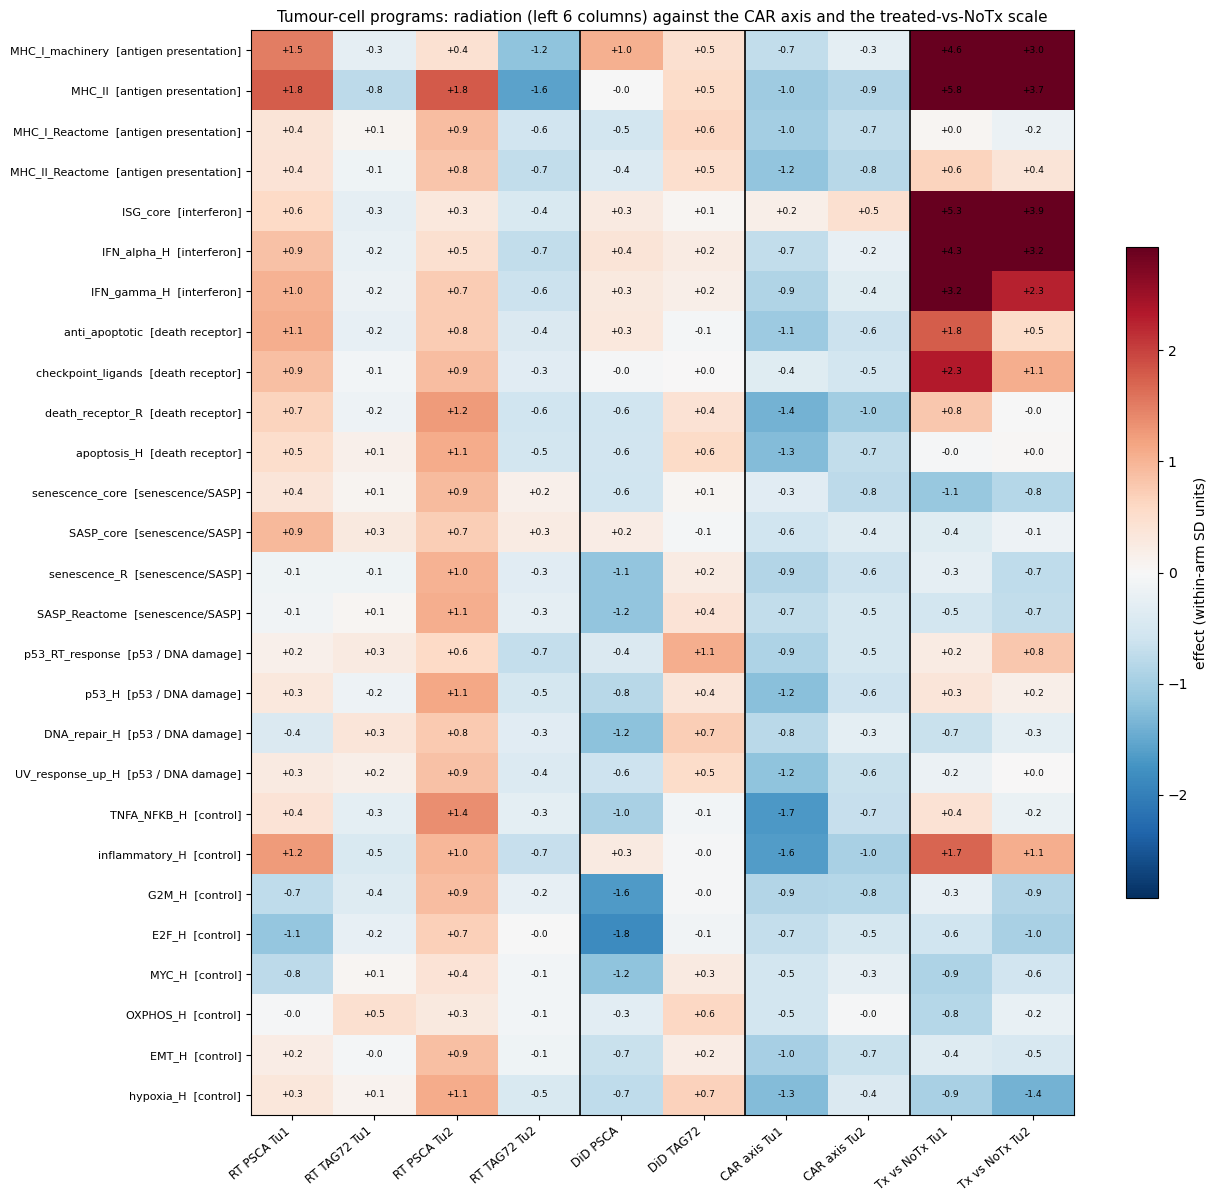

In [9]:
# (1) every program, every contrast, one heatmap — RT read against the CAR axis and NoTx scale
cols = {}
for site in (1, 2):
    r = RT[RT.site == site].set_index("program")
    cols[f"RT PSCA Tu{site}"] = r["d_PSCA"]; cols[f"RT TAG72 Tu{site}"] = r["d_TAG72"]
cols["DiD PSCA"] = DID["DiD_PSCA"]; cols["DiD TAG72"] = DID["DiD_TAG72"]
for site in (1, 2):
    cols[f"CAR axis Tu{site}"] = CARX[CARX.site == site].set_index("program")["main"]
for site in (1, 2):
    cols[f"Tx vs NoTx Tu{site}"] = BENCH[BENCH.site == site].set_index("program")["main"]
H = pd.DataFrame(cols)
order = [p_ for fam in FAMILY_ORDER for p_ in PROGRAMS if FAMILY[p_] == fam]
H = H.reindex(order)
fig, ax = plt.subplots(figsize=(13, 0.36*len(H) + 2.4))
lim = np.nanpercentile(np.abs(H.values), 97)
im = ax.imshow(H.values, cmap="RdBu_r", norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = H.values[i, j]
        if np.isfinite(v): ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=6.5)
ax.set_xticks(range(H.shape[1])); ax.set_xticklabels(H.columns, rotation=40, ha="right", fontsize=8.5)
ax.set_yticks(range(H.shape[0])); ax.set_yticklabels([f"{p_}  [{FAMILY[p_]}]" for p_ in H.index], fontsize=8)
for x in [3.5, 5.5, 7.5]: ax.axvline(x, color="k", lw=1.2)
plt.colorbar(im, ax=ax, shrink=0.6, label="effect (within-arm SD units)")
ax.set_title("Tumour-cell programs: radiation (left 6 columns) against the CAR axis and the "
             "treated-vs-NoTx scale", fontsize=11)
fig.tight_layout(); fig.savefig(FIG/"03_tumour_state_heatmap.png", dpi=220, bbox_inches="tight")
plt.show()

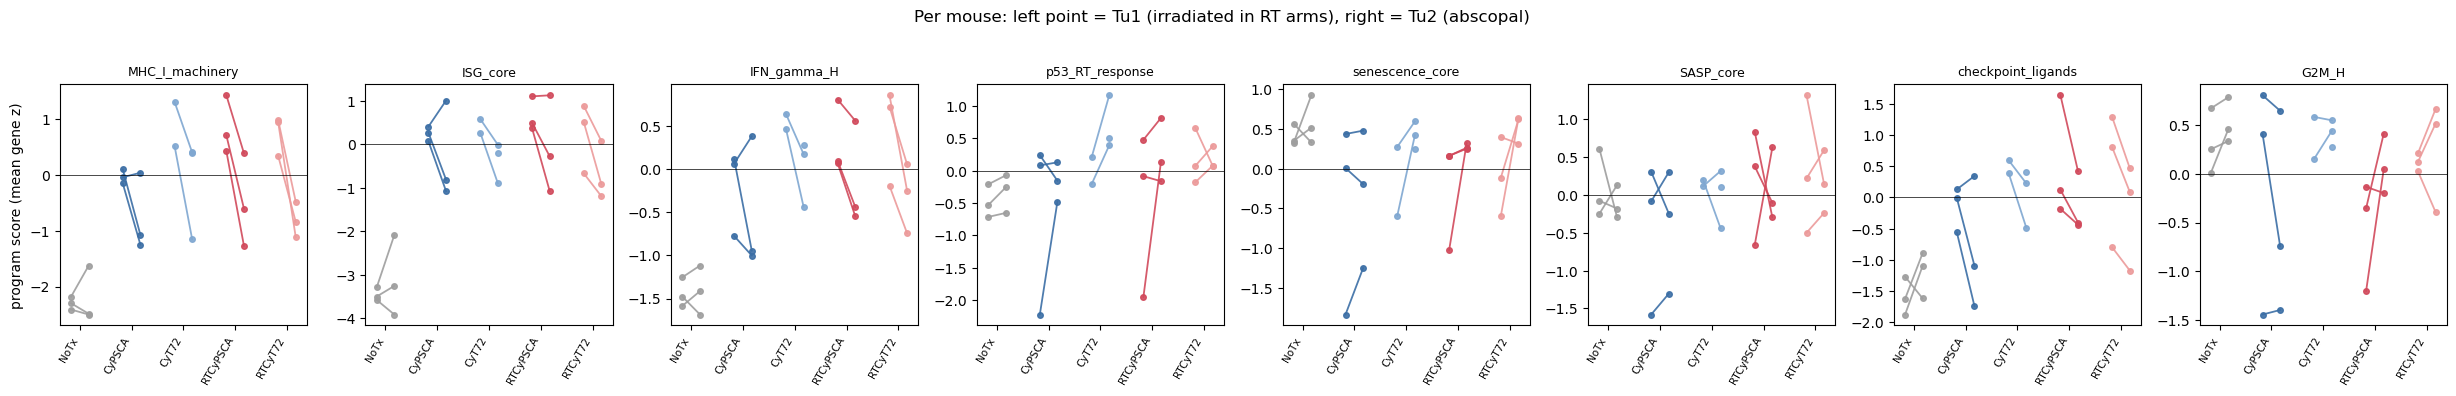

In [10]:
# (2) per-sample scores for the headline programs, one line per mouse Tu1 -> Tu2
SHOW = [p_ for p_ in ["MHC_I_machinery", "ISG_core", "IFN_gamma_H", "death_receptor",
                      "p53_RT_response", "senescence_core", "SASP_core", "checkpoint_ligands",
                      "G2M_H"] if p_ in S_T]
pc = S_T.join(meta)
fig, axes = plt.subplots(1, len(SHOW), figsize=(3.1*len(SHOW), 3.8), sharey=False)
for ax, prog in zip(np.atleast_1d(axes), SHOW):
    for i, arm in enumerate(ARM_ORDER):
        d = pc[pc.arm == arm]
        for _, g in d.groupby("mouse"):
            ys = [g.loc[g.site == s, prog].iloc[0] if (g.site == s).any() else np.nan for s in (1, 2)]
            ax.plot([i - .17, i + .17], ys, "-o", color=COL[arm], ms=4, lw=1.3, alpha=.9)
    ax.set_xticks(range(len(ARM_ORDER))); ax.set_xticklabels(ARM_ORDER, rotation=60, ha="right", fontsize=7.5)
    ax.set_title(prog, fontsize=9); ax.axhline(0, color="k", lw=.5)
axes[0].set_ylabel("program score (mean gene z)")
fig.suptitle("Per mouse: left point = Tu1 (irradiated in RT arms), right = Tu2 (abscopal)", y=1.03)
fig.tight_layout(); fig.savefig(FIG/"03_tumour_programs_per_mouse.png", dpi=220, bbox_inches="tight")
plt.show()

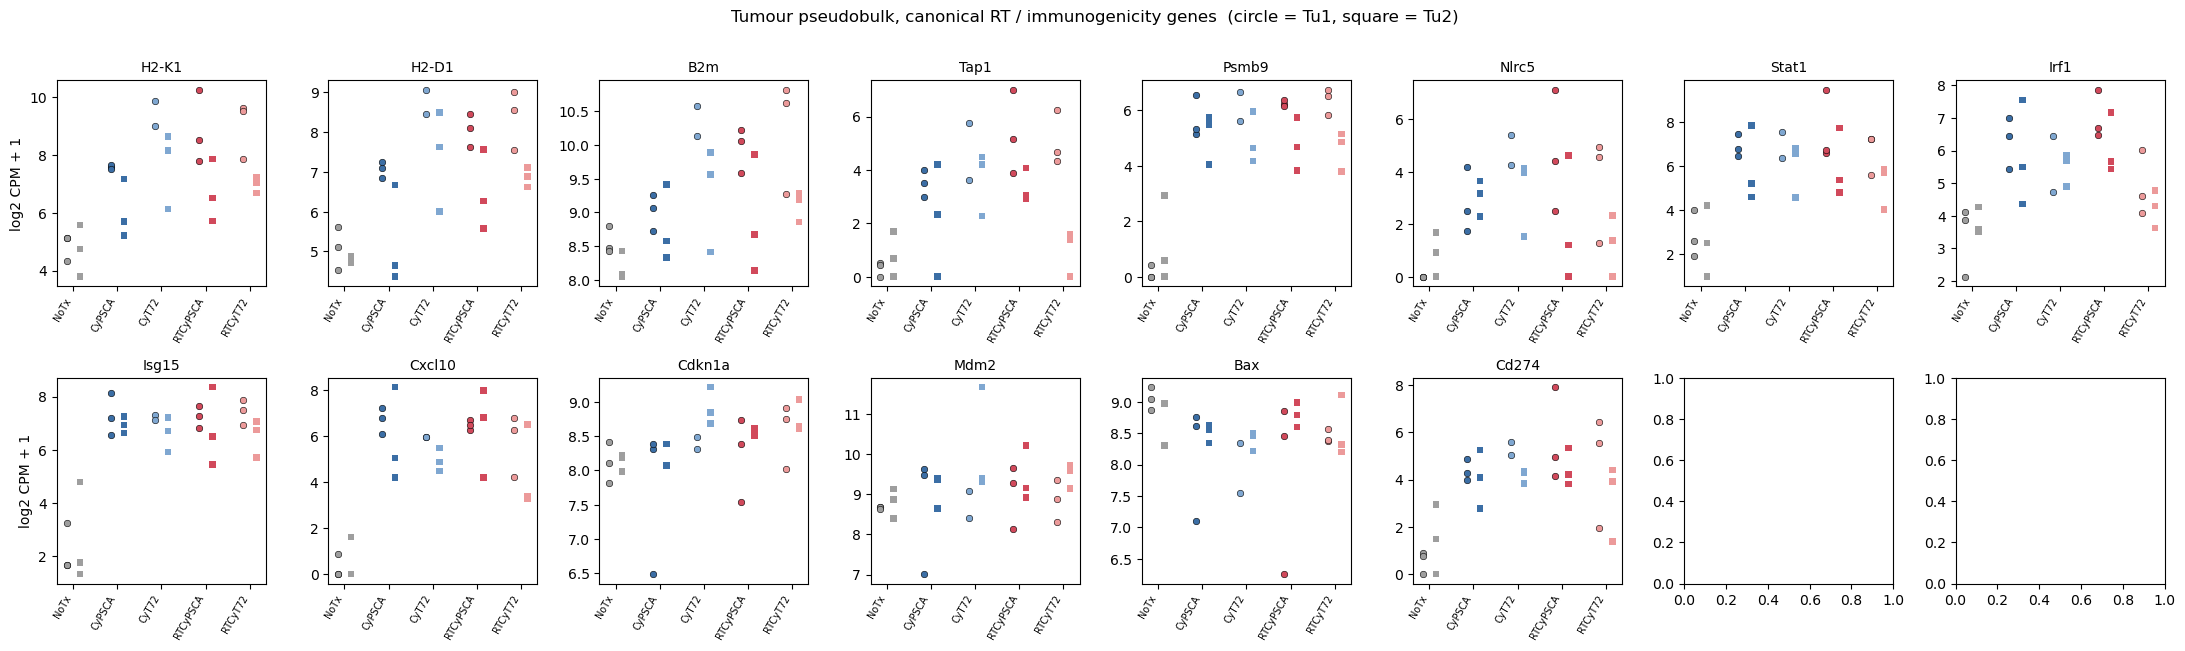

In [11]:
# (3) the canonical genes, so a program-level null can be checked gene by gene
GENES = [g for g in ["H2-K1", "H2-D1", "B2m", "Tap1", "Psmb9", "Nlrc5", "Stat1", "Irf1", "Isg15",
                     "Cxcl10", "Fas", "Tnfrsf10b", "Cdkn1a", "Mdm2", "Bax", "Cd274"] if g in L_T]
lc = L_T[GENES].join(meta)
fig, axes = plt.subplots(2, 8, figsize=(22, 6.4))
for ax, g in zip(np.ravel(axes), GENES):
    for i, arm in enumerate(ARM_ORDER):
        for s, mk in [(1, "o"), (2, "s")]:
            v = lc[(lc.arm == arm) & (lc.site == s)][g]
            ax.scatter(np.full(len(v), i + (s - 1.5)*0.3), v, color=COL[arm], marker=mk, s=22,
                       edgecolor="k" if s == 1 else "none", lw=.4)
    ax.set_title(g, fontsize=10); ax.set_xticks(range(len(ARM_ORDER)))
    ax.set_xticklabels(ARM_ORDER, rotation=60, ha="right", fontsize=7)
axes[0, 0].set_ylabel("log2 CPM + 1"); axes[1, 0].set_ylabel("log2 CPM + 1")
fig.suptitle("Tumour pseudobulk, canonical RT / immunogenicity genes  (circle = Tu1, square = Tu2)", y=1.01)
fig.tight_layout(); fig.savefig(FIG/"03_tumour_canonical_genes.png", dpi=200, bbox_inches="tight")
plt.show()

## 10. Summary

In [12]:
print("=" * 100); print("SUMMARY — report these back"); print("=" * 100)
print(f"\n[data] {len(L_T)} tumour pseudobulks (>= {MIN_CELLS} cells), "
      f"{int(design.n_tumour.sum()):,} Cancer_cells, median {design.n_tumour.median():.0f}/sample, "
      f"smallest {design.n_tumour.idxmin()} ({design.n_tumour.min():.0f})")
print(f"  {len(keep):,} genes kept | {len(PROGRAMS)} programs scored | "
      f"too sparse to score: {[k for k in coverage.index if k not in PROGRAMS]}")

print("\n[scale — median |effect| in within-arm SD units, and % program x site cells with p<0.05]")
for lbl, t in [("treated vs NoTx (pipeline check)", BENCH), ("CAR axis (PSCA - TAG72)", CARX),
               ("RT, between animals", RT)]:
    print(f"    {lbl:<34s} {t['main'].abs().median():.2f} SD   p<0.05 in {(t.p_main < 0.05).mean():5.1%}"
          f"   sign-agree {(t.sign_agree != 'disagree').mean():5.1%}")
print(f"    {'RT, within-mouse DiD':<34s} {DID['main'].abs().median():.2f} SD   p<0.05 in "
      f"{(DID.p_main < 0.05).mean():5.1%}   sign-agree {DID.sign_agree.mean():5.1%}")

LEAD = RT[(RT.sign_agree != "disagree") & (RT.p_main < 0.10) & (RT.rand_pct_main > 0.90)]
print(f"\n[RT main-effect leads: sign-agree in both backgrounds, p_main<0.10, beats 90% of random "
      f"programs] -> {len(LEAD)}")
for _, r in LEAD.sort_values("p_main").iterrows():
    cl = cmp_.query("program == @r.program and site == @r.site")
    print(f"    {SITE[r.site]:<10s} {r.program:<22s} [{r.family}]  PSCA {r.d_PSCA:+.2f}  TAG72 "
          f"{r.d_TAG72:+.2f}  p={r.p_main:.3f}  rand pct {r.rand_pct_main:.2f}  | without myeloid "
          f"genes {cl.main_no_myeloid_genes.iloc[0]:+.2f}, in macs {cl.main_in_macrophages.iloc[0]:+.2f}")

INT = RT[(RT.p_inter < 0.10) & (RT.rand_pct_inter > 0.90)]
print(f"\n[RT x CAR interaction leads: backgrounds move OPPOSITE ways, p_inter<0.10, beats 90% of "
      f"random] -> {len(INT)}")
for _, r in INT.sort_values("p_inter").iterrows():
    fm = amb.loc[r.program, "myeloid_dominant"] / amb.loc[r.program, "kept"]
    pm = RT_mac.query("program == @r.program and site == @r.site")
    pm_s = (f"in macs PSCA {pm.d_PSCA.iloc[0]:+.2f} TAG72 {pm.d_TAG72.iloc[0]:+.2f}"
            if len(pm) else "not scorable in macs")
    print(f"    {SITE[r.site]:<10s} {r.program:<22s} PSCA {r.d_PSCA:+.2f}  TAG72 {r.d_TAG72:+.2f}  "
          f"p_inter={r.p_inter:.3f} | {fm:.0%} myeloid-dominant genes"
          f"{'  <- AMBIENT-SUSPECT' if fm > 0.5 else ''} | {pm_s}")
print("  (a myeloid-dominant gene is one macrophages express > MYELOID_RATIO x more than tumour "
      "cells.\n   That makes it ambient-SUSPECT, not proven ambient — tumour cells do express MHC-I. "
      "\n   The test that would settle it is a program built only from tumour-restricted genes.)")

DL = DID[DID.sign_agree & (DID.p_main < 0.10)]
print(f"\n[within-mouse DiD leads (sign-agree, p<0.10)] -> {len(DL)}: "
      f"{[f'{i} {r.main:+.2f}' for i, r in DL.iterrows()]}")

print("\n[by family — mean RT main effect, SD units: irradiated | abscopal | DiD]")
for fam in FAMILY_ORDER:
    ps = [p_ for p_ in PROGRAMS if FAMILY[p_] == fam]
    a = RT[(RT.site == 1) & RT.program.isin(ps)]["main"].mean()
    b = RT[(RT.site == 2) & RT.program.isin(ps)]["main"].mean()
    c = DID.loc[ps, "main"].mean()
    print(f"    {fam:<22s} {a:+.2f} | {b:+.2f} | {c:+.2f}")

print("\n[how to read]")
print("  A main-effect claim needs: sign agreement, p_main small, AND beating random programs,")
print("  AND surviving removal of myeloid-dominant genes. The CAR-axis row is the realistic")
print("  yardstick; treated-vs-NoTx only shows the machinery can see anything.")
print(f"\n[files] {OUT}: tumour_program_scores_per_sample.csv, tumour_state_rt_contrasts.csv, "
      f"tumour_state_did.csv,\n        tumour_state_car_axis.csv, tumour_state_benchmark_treated_vs_notx.csv, "
      f"tumour_state_ambient_check.csv")
print(f"[figures] {FIG}: 03_tumour_state_heatmap.png, 03_tumour_programs_per_mouse.png, "
      f"03_tumour_canonical_genes.png")
print("=" * 100)

SUMMARY — report these back

[data] 29 tumour pseudobulks (>= 20 cells), 6,614 Cancer_cells, median 175/sample, smallest CyPSCA_Tu2_3 (36)
  7,967 genes kept | 27 programs scored | too sparse to score: ['cGAS_STING', 'death_receptor', 'STING_Reactome', 'TRAIL_Reactome']

[scale — median |effect| in within-arm SD units, and % program x site cells with p<0.05]
    treated vs NoTx (pipeline check)   0.68 SD   p<0.05 in 35.2%   sign-agree 57.4%
    CAR axis (PSCA - TAG72)            0.72 SD   p<0.05 in  3.7%   sign-agree 64.8%
    RT, between animals                0.24 SD   p<0.05 in  0.0%   sign-agree 22.2%
    RT, within-mouse DiD               0.23 SD   p<0.05 in  0.0%   sign-agree 25.9%

[RT main-effect leads: sign-agree in both backgrounds, p_main<0.10, beats 90% of random programs] -> 0

[RT x CAR interaction leads: backgrounds move OPPOSITE ways, p_inter<0.10, beats 90% of random] -> 5
    abscopal   MHC_II                 PSCA +1.79  TAG72 -1.56  p_inter=0.040 | 100% myeloid-domin